# EEG Processing - starting with epochs

This notebook is to perform EEG processing starting at the epochs.

## 📦 Imports

In [16]:
%matplotlib widget
import mindmap as mm
import mne

## 🧠 Data

📥 **<font color=pink>Inputs</font>**
- `eeg`: Raw EEGs

🎚️ **<font color=pink>Configuration</font>**:
- `fconfig`: Configuration file.
- `sub`: Subject id
- `samp`: EEG sample

In [17]:
# ------------ Parameters -------------
fconfig = "../../papers/intra/configuration.yml"
sub     = "50"
task    = "spk"
run     = None
# -------------------------------------

reader = mm.io.dataset_reader(fconfig)
data   = reader(sub, "eeg", task=task, run=run)

DATA SUMMARY
Dataset: intra
Subject: 50
Task: None
Run: None
Retrieved objects:
- eeg
Missing objects:


/home/nino/Code/mindmap/mindmap/io/dataset_readers.py:597: RuntimeWarning: Fiducial point nasion not found, assuming identity unknown to head transformation
  epochs = epochs.set_montage(montage, verbose="warning")


📊 **EEG signal**

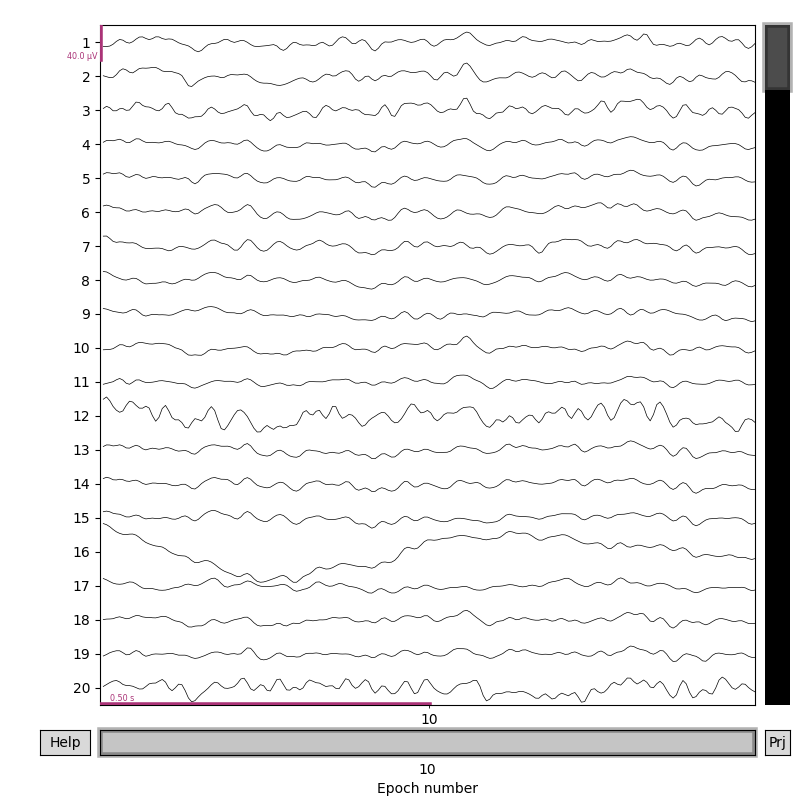

In [35]:
_ = data["eeg"][10].plot()

MNE type: <class 'mne.epochs.EpochsArray'>
Not setting metadata
130 matching events found
No baseline correction applied
0 projection items activated
combining channels using GFP (eeg channels)


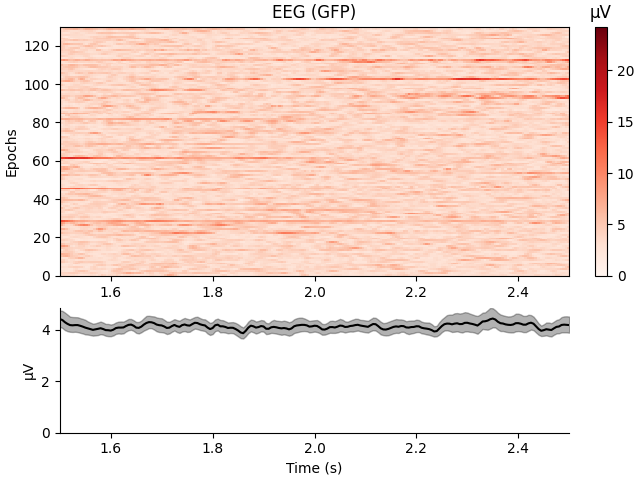

In [36]:
print(f"MNE type: {type(data['eeg'])}")
_ = data["eeg"].plot_image()

📊 **Temporal Fourier spectrum**

    Using multitaper spectrum estimation with 7 DPSS windows
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


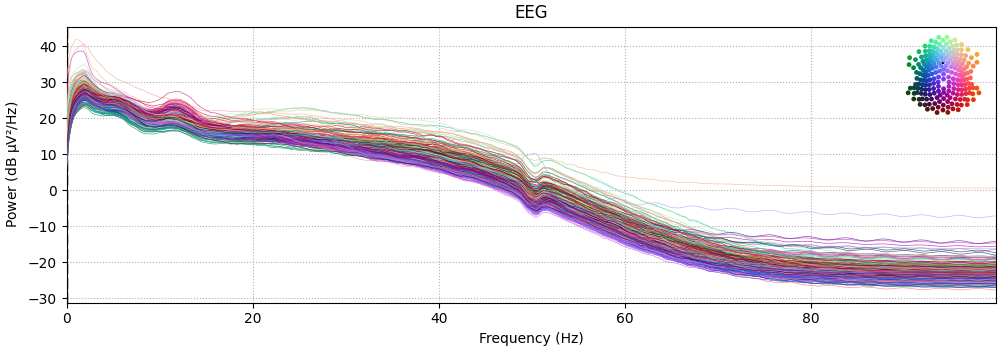

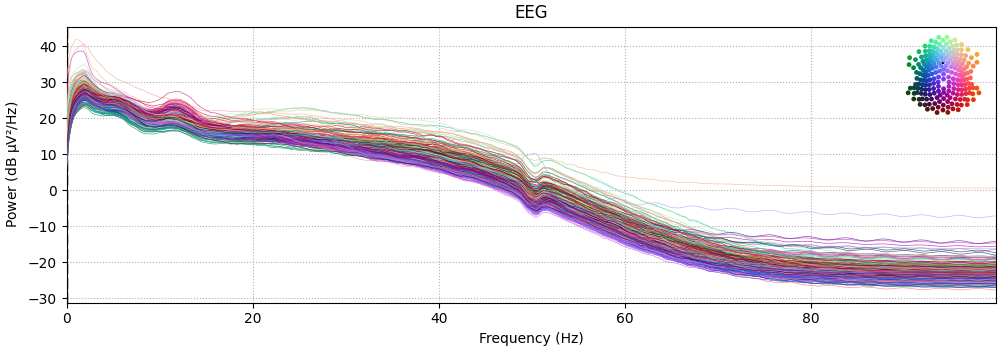

In [21]:
psd = data["eeg"].compute_psd().plot()

## ⚙️ 1. Process Raw

While the data are still in the raw stage, we should apply the necessary filters (such as a notch filter and, if needed, a band-pass filter), re-reference it (typically using average referencing), remove or interpolate bad channels, and remove artifacts.

#### Filters

**Notch filter**: A prevalent source of noise in recordings from electrical devices is the 50 Hz electrical interference. To mitigate this type of noise, it is advisable to apply a notch filter, which is a band-stop filter specifically designed to attenuate frequencies around 50 Hz.

In [22]:
# data["eeg"] = data["eeg"].filter(
#     l_freq = 63,
#     h_freq = 37,
#     picks  = "all",
#     method = "fir",
# )

#### Re-reference

An ideal reference signal captures none of the brain-specific fluctuations in electric potential while picking up all of the environmental noise and interference detected by the measurement electrodes. In practice, this means that the reference electrode is often placed on the subject's body, close to the head but as far away from the neural sources as possible. If the reference electrode also records neural sources, we can set a "virtual reference," which is the average of all channels.

In [23]:
data["eeg"] = data["eeg"].set_eeg_reference(ref_channels="average", projection=True)

EEG channel type selected for re-referencing
Adding average EEG reference projection.
1 projection items deactivated
Average reference projection was added, but has not been applied yet. Use the apply_proj method to apply it.


#### Interpolating bad channels

After observing the time series and Fourier transform, we can identify any electrodes that did not record properly. In such cases, we interpolate the faulty channels to prevent them from 
affecting the rest of the analysis. <br>

🎚️ **<font color=pink>Bad channels</font>**:
- `bads`: List of bad channels by name.

In [7]:
# ------------ Parameters -------------
bads = []
# -------------------------------------

for b in bads:
    data["eeg"].info["bads"].append(b)
data["eeg"] = data["eeg"].interpolate_bads(method={"eeg":"spline"})

Setting channel interpolation method to {'eeg': 'spline'}.


/tmp/ipykernel_21853/3322194614.py:7: RuntimeWarning: No bad channels to interpolate. Doing nothing...
  data["eeg"] = data["eeg"].interpolate_bads(method={"eeg":"spline"})


#### Remove artifacts
NOT IMPLEMENTED

📊 **New EEG signal**

In [13]:
_ = data["eeg"].plot(proj=True)

TypeError: BaseEpochs.plot() got an unexpected keyword argument 'proj'

📊 **New temporal Fourier spectrum**

Created an SSP operator (subspace dimension = 1)
1 projection items activated
SSP projectors applied...
Effective window size : 8.192 (s)
Plotting power spectral density (dB=True).


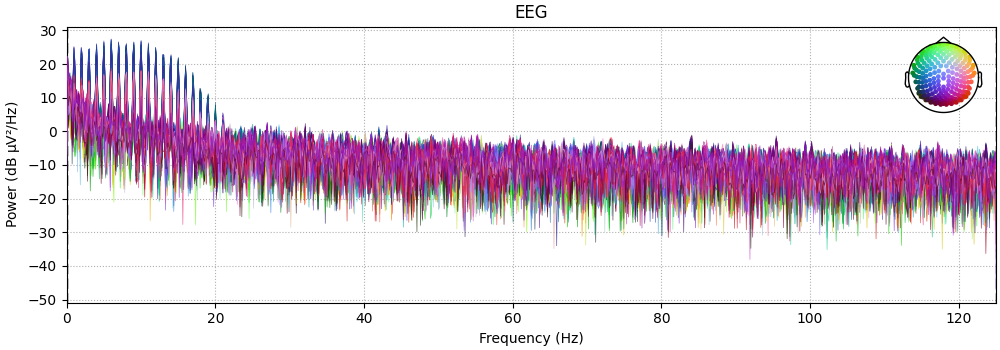

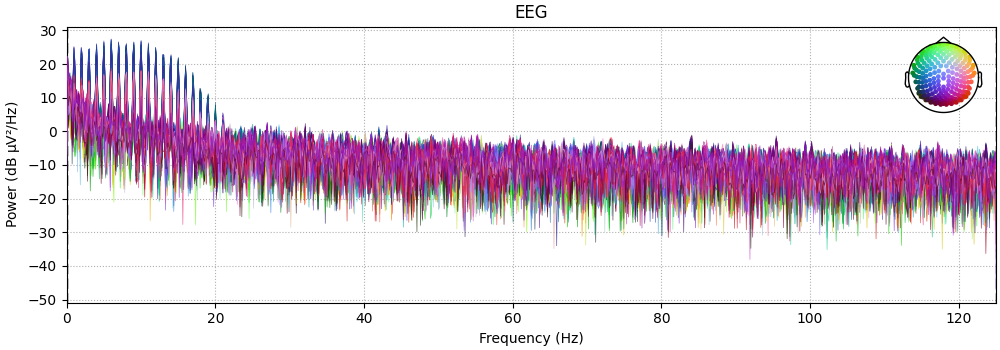

In [9]:
_ = data["eeg"].compute_psd(proj=True).plot()

#### Noise Covariance matrix

🎚️ **<font color=pink>noise covariance</font>**:
- `tmax`: Maximum time point to consider as noise.

Using data from preloaded Raw for 20 events and 225 original time points ...
    Created an SSP operator (subspace dimension = 1)
    Setting small EEG eigenvalues to zero (without PCA)
Reducing data rank from 203 -> 202
Estimating covariance using EMPIRICAL
Done.
Number of samples used : 1260
[done]
Computing rank from covariance with rank=None
    Using tolerance 7.8e-13 (2.2e-16 eps * 203 dim * 17  max singular value)
    Estimated rank (eeg): 202
    EEG: rank 202 computed from 203 data channels with 0 projectors


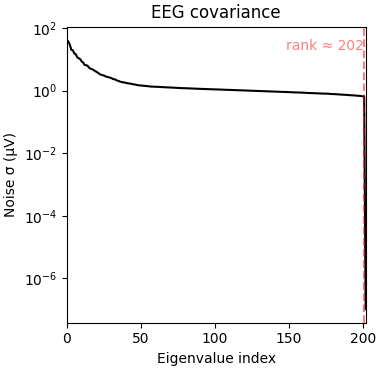

(<Figure size 380x370 with 2 Axes>, <Figure size 380x370 with 1 Axes>)

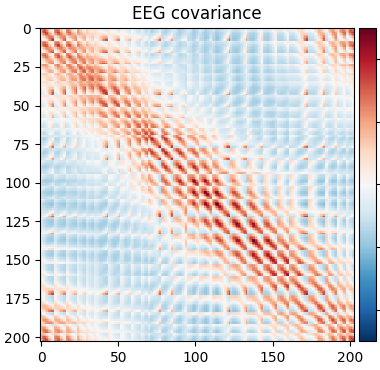

In [11]:
# ------------ Parameters -------------
tmax = baseline[1]
# -------------------------------------

noise_cov = mne.compute_covariance(epochs, tmax=tmax, method="empirical")       # uses projectors (avg ref) of epochs
noise_cov.plot(epochs.info)

## ⚙️ 3. Process Evoked

Here we average all the epochs. The result is known as an evoked potential. We will continue the processing by applying:
1. Average referencing
2. Baseline correction
3. Notch filtering

#### Averaging epochs

Created an SSP operator (subspace dimension = 1)
1 projection items activated
SSP projectors applied...


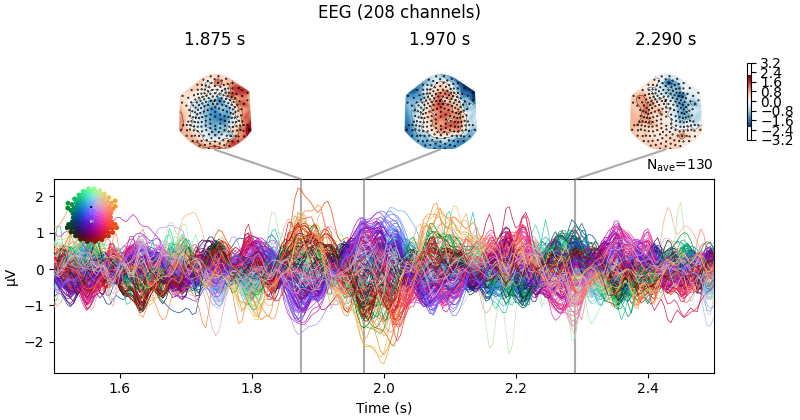

In [31]:
# -------- Parameters ----------

tmin = 1.5
tmax = 2.5

# ------------------------------


epochs = data["eeg"]
evoked = epochs.crop(tmin=tmin, tmax=tmax).average()
_ = evoked.plot_joint(topomap_args={"extrapolate":"local"})

💾 **Save processed EEG and noise covariance**

🎚️ **<font color=pink>Options</font>**:
- `overwrite`: Overwrites if file already exists.

In [13]:
# save EEG
file = mm.io.get_bidspath(
    root     = reader.config["MM_DIR"],
    subject  = data["sub"],
    datatype = "ave",
    session  = None,
    task     = data["task"],
    run      = data["run"],
)

mm.io.mkdir(file)
evoked.save(file, overwrite=True)
print(f"\033[92mSuccessfully saved preprocessed EEG for subject '{data['sub']}', task '{data['task']}, run {data['run']}.\033[0m")

# save noise covariance
file = mm.io.get_bidspath(
    root     = reader.config["MM_DIR"],
    subject  = data["sub"],
    datatype = "cov",
    session  = None,
    task     = data["task"],
    run      = data["run"],
)

mm.io.mkdir(file)
noise_cov.save(file, overwrite=True)
print(f"\033[92mSuccessfully saved noise covariance for subject '{data['sub']}', task '{data['task']}, run {data['run']}.")

Successfully saved preprocessed EEG for subject '10', task 'rest, run 11.
Successfully saved noise covariance for subject '10', task 'rest, run 11.
